# MAE 6246 — Week 11: Designing a controller and an observer for a MuJoCo model
**Linear Systems and Control · November 6, 2026**

In Weeks 9 and 10 we designed a state-feedback gain $K$ and an observer gain $L$ for the beam with a sliding mass, and in the Week 10 MuJoCo example we applied them to a nonlinear physics engine. Today the roles are separated. A provided module, `mjsim.py`, supplies the dynamic model: its linear model $(A,B,C,D)$ about an equilibrium and a MuJoCo simulation of the nonlinear motion. **Your task is to design $K$ and $L$ from the linear model and implement the controller and observer**; `mjsim` then tests them on MuJoCo. You never call MuJoCo directly, and every model in `mjsim` is used through the same commands.

Run all cells in order. The first cell installs missing dependencies and downloads `mjsim.py` when it is not already present. For local use, extract the downloadable example bundle and keep `mjsim.py` in the same folder as this notebook.

1. Load the dynamics, its equilibrium, and its linear model.
2. Connect a controller and an observer to the simulation.
3. Design the state-feedback gain $K$ and test full-state feedback.
4. Design the observer gain $L$ and implement it as a sampled update.
5. Test output feedback on MuJoCo with an explicit initial estimate.
6. Experiments.

In [ ]:
import importlib.util
import subprocess
import sys

packages = {"mujoco": "mujoco==3.17.0", "numpy": "numpy", "scipy": "scipy",
            "matplotlib": "matplotlib", "imageio_ffmpeg": "imageio-ffmpeg"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
print("Dependencies ready.")

from pathlib import Path
from urllib.request import urlretrieve

module = Path("mjsim.py")
if not module.is_file():
    module_url = ("https://raw.githubusercontent.com/fdcl-gwu/MAE6246/"
                  "main/notebooks/week11/mjsim.py")
    urlretrieve(module_url, module)
    print("Downloaded mjsim.py from the course repository.")


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import place_poles
from IPython.display import Video
import mjsim

np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 11})

## 1. Load the dynamics
Use $x=[d,\dot d,\theta,\dot\theta]^T$, where $d$ is the position of the mass from the pivot and $\theta$ is the beam angle, positive when the right-hand end rises. The input $u$ is the motor torque at the pivot, and only the beam angle is measured, $y=\theta$. As in Week 10, $m=1\,\mathrm{kg}$, $I=2\,\mathrm{kg}\,\mathrm{m}^2$, and $g=9.81\,\mathrm{m}/\mathrm{s}^2$.

The MuJoCo model integrates the nonlinear motion. Its linear model about the centered, horizontal equilibrium is
$$
\ddot d=-g\theta,\qquad I\ddot\theta=-mgd+u,\qquad y=\theta .
$$

As in Week 9, the linear model describes deviations from an operating point $(x_\star,u_\star)$ with output $y_\star$. With $\delta x=x-x_\star$, $\delta u=u-u_\star$, and $\delta y=y-y_\star$,
$$
\delta\dot x=A\,\delta x+B\,\delta u,\qquad \delta y=C\,\delta x+D\,\delta u .
$$
`mjsim` returns the equilibrium as `x_eq`, `u_eq`, `y_eq`, so that $x_\star=$ `x_eq`, $u_\star=$ `u_eq`, and $y_\star=$ `y_eq`. For the beam, all three are zero. The simulation itself always works with the physical $x$, $u$, and $y$.

`load_dynamics` also sets the sample period $\Delta t$ (`dt`, 2 ms by default) and an optional torque limit. Loading checks with MuJoCo that $(x_\star,u_\star)$ is an equilibrium.

In [3]:
beam_dyn = mjsim.load_dynamics("beam", u_limit=10.0)   # |u| <= 10 N m
beam_dyn.info()

A, B, C, D = beam_dyn.A, beam_dyn.B, beam_dyn.C, beam_dyn.D      # linear model
x_eq, u_eq, y_eq = beam_dyn.x_eq, beam_dyn.u_eq, beam_dyn.y_eq   # equilibrium
n, m, p, dt = beam_dyn.n, beam_dyn.m, beam_dyn.p, beam_dyn.dt    # dimensions, sample period

Dynamics 'beam':  n = 4 states, m = 1 inputs, p = 1 outputs, dt = 0.002 s
  x = ['d [m]', 'd_dot [m/s]', 'theta [rad]', 'theta_dot [rad/s]']
  u = ['torque [N m]']
  y = ['theta [rad]']
  equilibrium 'level': x_eq = [0. 0. 0. 0.]  u_eq = [0.]  y_eq = [0.]
  |u| <= [10.]
A =
[[ 0.     1.     0.     0.   ]
 [ 0.     0.    -9.81   0.   ]
 [ 0.     0.     0.     1.   ]
 [-4.905  0.     0.     0.   ]]
B =
[[0. ]
 [0. ]
 [0. ]
 [0.5]]
C =
[[0. 0. 1. 0.]]
D =
[[0.]]


### 1.1. Controllability and observability
Before designing $K$ and $L$, confirm that $(A,B)$ is controllable and $(A,C)$ is observable (Week 5).

In [4]:
Ctrb = np.hstack([np.linalg.matrix_power(A, j) @ B for j in range(n)])
O = np.vstack([C @ np.linalg.matrix_power(A, j) for j in range(n)])
print("Open-loop poles:", np.linalg.eigvals(A))
print("Controllability rank:", np.linalg.matrix_rank(Ctrb))
print("Observability rank:", np.linalg.matrix_rank(O))

Open-loop poles: [-2.6338+0.j      0.    +2.6338j  0.    -2.6338j  2.6338+0.j    ]
Controllability rank: 4
Observability rank: 4


## 2. Connect a controller and an observer
The controller and the observer are ordinary Python functions with fixed arguments. They use only the linear model and the measurements; neither calls MuJoCo.

| Function | Call | Returns |
|---|---|---|
| controller | `u = controller(t, xhat)` | input from the current estimate $\hat x_k$ |
| observer | `xhat_next = observer(t, xhat, u, y)` | next estimate $\hat x_{k+1}$ from $\hat x_k$, the applied $u_k$, and the measured $y_k$ |

At each sample $t_k=k\Delta t$, `mjsim.simulate` computes the torque from the current estimate, measures the angle, predicts the next estimate, and advances MuJoCo for one sample period under the held torque:

```python
u = controller(t, xhat)          # saturated to the torque limit, if any
y = measure()                    # beam angle from the MuJoCo sensor
xhat_next = observer(t, xhat, u, y)
# MuJoCo advances for dt under u.
xhat = xhat_next
```

This is the same digital implementation as the Week 10 MuJoCo example. With `observer=None`, the controller receives the actual state instead (full-state feedback). The command is the same for the MuJoCo model and for its linear model, `beam_dyn.linear()`:

```python
result = mjsim.simulate(beam_dyn, x0, T, controller, observer)
result.t, result.x, result.xhat, result.u, result.y
```

Each function is built by a *factory* that receives the dynamics and the gain and returns the function. The gain is fixed when the function is built, so different designs can be compared side by side.

## 3. Design the state-feedback gain $K$
In deviation coordinates, state feedback is $\delta u=-K\,\delta\hat x$ (Week 9), so the physical command is
$$
u=u_\star-K(\hat x-x_\star).
$$
Choose controller poles $-1,-1.5,-2,-2.5$, as in Week 10.

In [5]:
def make_controller(dyn, K):
    x_eq, u_eq = dyn.x_eq, dyn.u_eq
    def controller(t, xhat):
        return u_eq - K @ (xhat - x_eq)
    return controller

controller_poles = np.array([-1., -1.5, -2., -2.5])
K = place_poles(A, B, controller_poles).gain_matrix
print("K =", K)
print("Poles of A-BK:", np.sort(np.linalg.eigvals(A - B @ K)))

K = [[-11.3391  -3.9246  35.5     14.    ]]
Poles of A-BK: [-2.5+0.j -2. +0.j -1.5+0.j -1. +0.j]


### 3.1. Full-state feedback
First test the gain with the actual state, `observer=None`. Start at $d(0)=8$ cm and $\theta(0)=2^\circ$ with zero velocities. The same command simulates the MuJoCo model and its linear model.

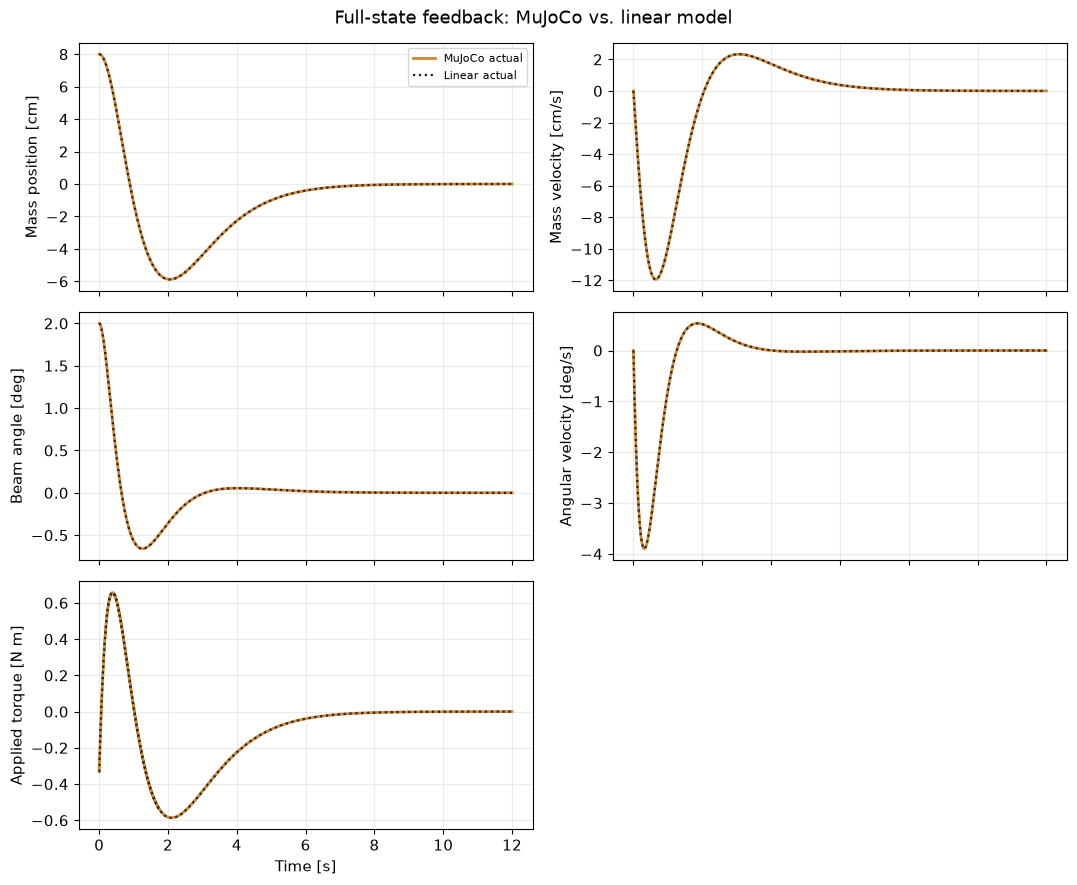

In [6]:
x0 = np.array([0.08, 0., np.deg2rad(2.), 0.])
T = 12.0
state_mj  = mjsim.simulate(beam_dyn,          x0, T, make_controller(beam_dyn, K))
state_lin = mjsim.simulate(beam_dyn.linear(), x0, T, make_controller(beam_dyn, K))
mjsim.plot_response([state_mj, state_lin], labels=["MuJoCo", "Linear"],
                    title="Full-state feedback: MuJoCo vs. linear model")
plt.show()

### 3.2. Animate the full-state feedback response
Replay the recorded MuJoCo trajectory `state_mj` from Section 3.1. The controller uses the actual state, and no observer is used. The orange sphere marks the sliding point mass; nothing is simulated again.


In [ ]:
Video(mjsim.animate(state_mj, "week11_beam_state_feedback.mp4"), embed=True)

## 4. Design the observer gain $L$
In deviation coordinates, the observer from Week 10 is
$$
\delta\dot{\hat x}=A\,\delta\hat x+B\,\delta u+L(\delta y-C\,\delta\hat x-D\,\delta u),
$$
so the estimation error $e=x-\hat x$ of the linear model satisfies $\dot e=(A-LC)e$. Choose observer poles $-3,-4,-5,-6$ and place them through the dual pair $(A^T,C^T)$.

### 4.1. Sampled implementation
The angle is measured only at the samples, and the torque is held over each sample period. With $\delta u$ and $\delta y$ held, the observer equation
$$
\delta\dot{\hat x}=(A-LC)\,\delta\hat x+(B-LD)\,\delta u+L\,\delta y
$$
is solved **exactly** over one period by its zero-order-hold discretization (Week 5):
$$
\hat x_{k+1}=x_\star+A_o(\hat x_k-x_\star)+B_o(u_k-u_\star)+L_o(y_k-y_\star).
$$
`mjsim.discretize(A, B, dt)` returns $(A_d,B_d)$ with $x_{k+1}=A_dx_k+B_dw_k$ for an input $w$ held over $\Delta t$. Here $w=[\delta u;\,\delta y]$, so the columns of $B_d$ split into $B_o$ and $L_o$. The factory takes the model, the equilibrium, and $\Delta t$ from the dynamics, so its only design input is $L$.

With a torque limit, the simulator passes the **applied, saturated torque** to the observer.

In [7]:
def make_observer(dyn, L):
    A, B, C, D, m, dt = dyn.A, dyn.B, dyn.C, dyn.D, dyn.m, dyn.dt
    x_eq, u_eq, y_eq = dyn.x_eq, dyn.u_eq, dyn.y_eq
    Ad, Bd = mjsim.discretize(A - L @ C, np.hstack([B - L @ D, L]), dt)
    Ao, Bo, Lo = Ad, Bd[:, :m], Bd[:, m:]
    def observer(t, xhat, u, y):
        return x_eq + Ao @ (xhat - x_eq) + Bo @ (u - u_eq) + Lo @ (y - y_eq)
    return observer

observer_poles = np.array([-3., -4., -5., -6.])
L = place_poles(A.T, C.T, observer_poles).gain_matrix.T
print("L =", L.ravel())
print("Poles of A-LC:", np.sort(np.linalg.eigvals(A - L @ C)))

L = [-69.7248 -83.2045  18.     119.    ]
Poles of A-LC: [-6.+0.j -5.+0.j -4.+0.j -3.+0.j]


## 5. Output feedback on MuJoCo
The controller now uses only the estimate, and the observer only the measured angle and the applied torque. Set the initial estimate explicitly with `xhat0 = x_eq.copy()` and pass it to `simulate`. Thus $\hat x(0)=x_\star$, while the actual state starts at $x(0)$ above. Change `xhat0` to explore other initial estimates.


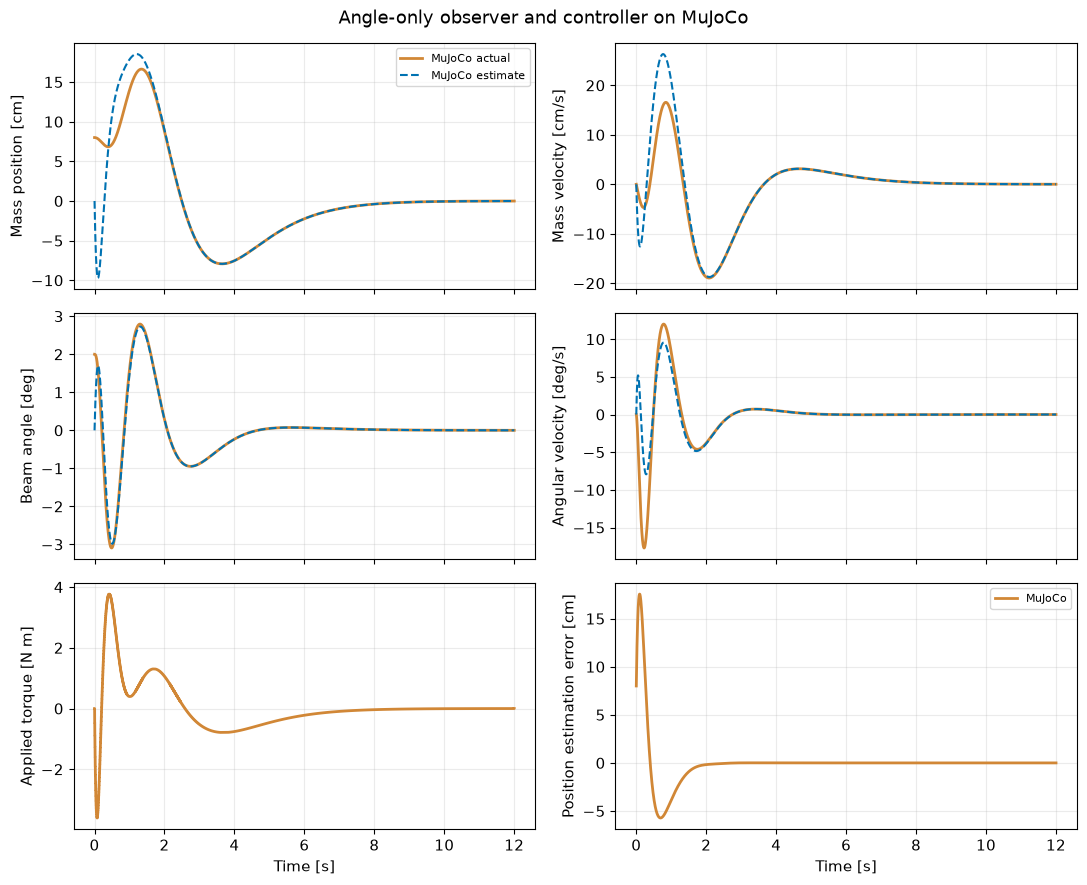

Peak torque: 3.769 N m
Final position and estimation error: -0.058 mm, 0.000 mm


In [8]:
controller = make_controller(beam_dyn, K)
observer = make_observer(beam_dyn, L)
xhat0 = x_eq.copy()   # initial estimate: [d, d_dot, theta, theta_dot]
output_mj = mjsim.simulate(beam_dyn, x0, T, controller, observer, xhat0=xhat0)
mjsim.plot_response(output_mj, labels=["MuJoCo"],
                    title="Angle-only observer and controller on MuJoCo")
plt.show()

print("Peak torque: %.3f N m" % np.max(np.abs(output_mj.u)))
print("Final position and estimation error: %.3f mm, %.3f mm"
      % (1000*output_mj.x[-1, 0], 1000*(output_mj.x[-1, 0] - output_mj.xhat[-1, 0])))


**Discuss:** The estimation error grows before it decays: stable observer poles do not imply monotonic error reduction. The mass first moves away from the pivot before returning. On MuJoCo, the error is also driven by the difference between the nonlinear motion and the linear model used by the observer. With the same gains and initial estimate as Week 10, the peak torque is about 3.8 N m.


### 5.1. Animate the MuJoCo response
The video replays the recorded MuJoCo trajectory; nothing is simulated again. The orange sphere marks the sliding point mass.

In [10]:
Video(mjsim.animate(output_mj, "week11_beam_output_feedback.mp4"), embed=True)

## 6. Experiments
1. Move the controller poles faster or slower. How do the settling time and the peak torque change? When does the 10 N m limit become active, and what happens then?
2. Move the observer poles closer to the controller poles, or make them faster. How does the estimation transient affect the response?
3. Set `xhat0 = x0.copy()` and rerun Section 5 to start with a correct estimate. Does the estimation error stay at zero on MuJoCo?
4. Increase the initial displacement and angle together, e.g., use `3*x0` as the initial state in Section 5 while keeping `xhat0` fixed. How do the response and estimation error change?
5. Add noise to the measured angle, `mjsim.simulate(..., noise_std=np.deg2rad(0.02))`. Compare the observer poles above with poles twice as fast.
6. Reload the dynamics with a longer sample period, e.g., `mjsim.load_dynamics("beam", dt=0.05, u_limit=10.0)`, and rebuild the controller and observer with the same $K$ and $L$. Rerun Section 5 and compare the response and estimation error with the 2 ms case. Why does an accurate physics integrator not guarantee stability of a slowly sampled controller?

**References:** Week 9 (state feedback), Week 10 (observers and the separation principle), Week 5 (exact discretization), and [MuJoCo Python](https://mujoco.readthedocs.io/en/stable/python.html).